# Experiment 01 — Behavioral diversity: selected five settings

**Main panel: Persona off, 155, 001, 003 and 046**, matching the semantic and Experiment 09 panels. Off/155/001 have three original trials; 003/046 have one. All main tables and figures use only these five settings. The frozen input retains the larger historical panel for provenance, but it is not the display cohort.

| Analysis | Location |
|---|---|
| Communication, collaboration and clarification behavior | This notebook |
| Within-conversation repetition and fact recovery | [Experiment 09](../09_offline_metric_suite/metric_suite.ipynb) |
| Semantic diversity and illustrative trajectories | [Semantic analysis](semantic_trajectory_analysis.ipynb) |
| Task performance | [Experiment 02](../02_performance_and_fields/) |

This notebook reads saved original-trial results and recorded API usage. It makes no new model calls, recomputes recorded-token estimates for the selected settings and reuses other saved metrics, and writes no repository data, reports or figure exports. Completed scientific failures can contribute when their traces are complete; infrastructure-truncated traces do not. Cancelled jobs, repairs, Sol and the newer SciConv protocol are excluded. Historical expanded-panel results remain in [the archived report](ALL_PERSONAS_BEHAVIOR.md).


**Latest compact figure:** Section 5 shows four persona-pair heatmaps using total simulator/actor output tokens, revision requests and clarification recall. Earlier token-decomposition figures remain as supporting analysis.

In [1]:
from pathlib import Path
import sys, json, hashlib
from IPython.display import display, Markdown, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
BASE=ROOT/'Experiment/01_behavioral_diversity'
DATA=BASE/'data/behavior_all_personas'
FIG=BASE/'figures/behavior_all_personas'
sys.path.insert(0,str(ROOT/'Experiment/shared'))
from analysis_utils import SOURCES, NAMES, label, cell, markdown_table
snapshot=json.loads((DATA/'snapshot.json').read_text())
summary=json.loads((DATA/'summary.json').read_text())
ALL_ARMS=summary['arms']
ARMS=['persona_off','candidate_155','candidate_001','candidate_003','candidate_046']
assert len(snapshot['episodes'])==4200
assert len({(r['trial'],r['source'],r['task_id'],r['arm']) for r in snapshot['episodes']})==4200

def metric_table(metric, group='all'):
    absolute=summary['absolute'][metric][group]
    paired=summary['paired'][metric][group]
    display(Markdown('**'+summary['metrics'][metric]['label']+'**'+(' · '+NAMES.get(group,group) if group!='all' else '')))
    display(Markdown(markdown_table(['Setting','Mean [95% CI]; tasks/episodes','Paired change vs off [95% CI]; tasks/pairs'],[
        [label(a),cell(absolute[a]),'reference' if a==ARMS[0] else cell(paired[a],True)] for a in ARMS])))

print('Read-only inputs:')
for name in ['snapshot.json','summary.json']:
    print(name,hashlib.sha256((DATA/name).read_bytes()).hexdigest())

import tempfile,subprocess
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from collections import defaultdict
from analysis_utils import paired
sys.path.insert(0,'/home/siyangwu/.codex/skills/nature-figure/scripts')
from audit_panel_alignment import require_matplotlib_panel_alignment
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'axes.titlesize':8,'axes.labelsize':7,'xtick.labelsize':6,'ytick.labelsize':6,'pdf.fonttype':42,'svg.fonttype':'none','axes.spines.top':False,'axes.spines.right':False})
COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
def checked_figure(fig,name,groups,exclude=()):
    # Notebook-only artifacts; editable exports and QA are temporary.
    with tempfile.TemporaryDirectory(prefix='psb-five-behavior-') as tmp:
        p=Path(tmp);fig.canvas.draw()
        measured=[ax for group in groups for ax in group if ax not in exclude]
        panel_ids={ax:'panel_'+str(i) for i,ax in enumerate(measured)}
        row_map={};col_map={}
        for ax in measured:
            box=ax.get_position();row_map.setdefault(round(box.y0,4),[]).append(panel_ids[ax]);col_map.setdefault(round(box.x0,4),[]).append(panel_ids[ax])
        require_matplotlib_panel_alignment(fig,axes=measured,panel_ids=panel_ids,row_groups=[v for v in row_map.values() if len(v)>1],column_groups=[v for v in col_map.values() if len(v)>1],json_out=str(p/'alignment.json'),overlay_svg=str(p/'alignment.svg'),exclude_axes=list(exclude),tolerance_pt=1.5,strict=True)
        for ext in ['pdf','svg','png']:
            fig.savefig(p/(name+'.'+ext),dpi=300,facecolor='white')
        audit=Path('/home/siyangwu/.codex/skills/nature-figure/scripts')
        for args in [[str(audit/'audit_pdf_text.py'),str(p/(name+'.pdf')),'--min-pt','5','--json'],[str(audit/'audit_figure_collisions.py'),str(p/(name+'.pdf')),'--json-out',str(p/'collisions.json')]]:
            result=subprocess.run([sys.executable,*args],capture_output=True,text=True)
            if result.returncode:raise RuntimeError(result.stdout+result.stderr)
        display(Image(filename=str(p/(name+'.png')),width=1100))
    plt.close(fig)

selected_episodes=[r for r in snapshot['episodes'] if r['arm'] in ARMS]
assert len(selected_episodes)==2200


Read-only inputs:
snapshot.json 37e6d1029ed7690347d94c62d66e728e82e4f552794005c6e78946f740276e00
summary.json 206a8624fdeafa106f648c2065c99cd2b5b32558e59317f029876d5d551a20e6


### Recorded output and reasoning tokens

The main tables and heatmap now separate **non-reasoning output tokens** from **reasoning tokens** for both roles. Non-reasoning output = recorded `completion_tokens` − recorded `reasoning_tokens`. It includes generated text, structured fields and tool-call arguments, so it is not exclusively visible prose. Total output is retained as a supporting reference. No text retokenization or estimated character-to-token conversion is used.

- **Simulator:** mean output tokens per noninitial decision/reply call. Structured decision fields and reasoning are included. Initial request-generation calls are excluded for non-SciConv workflows.
- **Actor:** sum output tokens across calls up to each `end_researcher_turn` handoff, then average completed handoffs within episode. Tool-call generation and reasoning are included. Calls after the last completed handoff are excluded. In SciConv, one call corresponds to each clarification question; the final-specification call is excluded to retain the prior behavioral endpoint.
- **Missingness:** absent usage/reasoning counts are missing, not zero; missing/misaligned logs do not acquire invented estimates. Call-to-turn counts are checked against the frozen episode features. Recorded zero reasoning remains a valid zero.
- **Aggregation:** episode means average within question, then benchmarks receive equal weight. Paired task/trial contrasts and 20,000 source-study bootstrap CIs are recomputed. The data coverage is reported separately for each metric.

These are computational expenditure measures for interactions, not counts of visible reply text alone. Reasoning is already part of total output and must not be added twice. Extraction records API-log SHA256 hashes in memory and verifies original event hashes; only numeric summaries and figures are embedded.

In [2]:
# Read API usage only; no retokenization, tokenizer downloads, or model calls.
from concurrent.futures import ThreadPoolExecutor
from analysis_utils import summarize
from collections import Counter
FIELDS=['simulator_tokens','actor_tokens','simulator_reasoning_tokens','actor_reasoning_tokens','simulator_nonreasoning_tokens','actor_nonreasoning_tokens']
def episode_key(r):return (r['trial'],r['source'],r['task_id'],r['arm'])
logs={episode_key(r):r for r in snapshot['event_logs']}
def api_usage(r):
    values={field:None for field in FIELDS}
    if not r['eligible']:return values,{'status':'incomplete_episode'}
    ref=logs[episode_key(r)];event_path=ROOT/ref['path']
    assert hashlib.sha256(event_path.read_bytes()).hexdigest()==ref['sha256']
    p=event_path.parent/'api_calls.private.jsonl'
    if not p.exists():p=event_path.parent/'api_calls.jsonl'
    if not p.exists():return values,{'status':'missing_api_log'}
    calls={'actor':[],'researcher':[]};digest=hashlib.sha256()
    with p.open('rb') as f:
        for line in f:
            digest.update(line)
            if not line.strip():continue
            c=json.loads(line)
            if c.get('phase')=='request':continue # EXP request/response records share call_id
            role=c.get('role')
            if role not in calls:continue
            usage=c.get('usage') or (c.get('response') or {}).get('usage') or {};total=usage.get('completion_tokens');reason=(usage.get('completion_tokens_details') or {}).get('reasoning_tokens')
            if total is not None:assert isinstance(total,(int,float)) and total>=0
            if reason is not None:assert isinstance(reason,(int,float)) and reason>=0 and (total is None or reason<=total)
            response=c.get('response') or {};choices=response.get('choices') or []
            message=choices[0].get('message',{}) if choices else {}
            tools=message.get('tool_calls') or []
            handoff=any(x.get('function',{}).get('name')=='end_researcher_turn' for x in tools)
            calls[role].append({'total':total,'reason':reason,'handoff':handoff})
    sci=r['source']=='sciconvbench'
    sim=calls['researcher'] if sci else calls['researcher'][1:] # omit initial planning request
    actor_groups=[];tail=[]
    if sci:
        # Preserve original behavior endpoint: questions only, exclude final specification.
        if len(calls['actor'])==r['actor_handoffs_or_questions']+1:
            actor_groups=[[c] for c in calls['actor'][:-1]]
    else:
        for c in calls['actor']:
            tail.append(c)
            if c['handoff']:actor_groups.append(tail);tail=[]
        if len(actor_groups)!=r['actor_handoffs_or_questions']:actor_groups=[]
    # Call usage includes structured decision fields, reasoning and actor tool generation.
    # Do not claim it is the number of tokens in the shared visible message alone.
    if len(sim)!=r['simulator_replies']:sim=[]
    for role,groups in [('simulator',[[c] for c in sim]),('actor',actor_groups)]:
        for source,field in [('total',role+'_tokens'),('reason',role+'_reasoning_tokens')]:
            if groups and all(c[source] is not None for g in groups for c in g):
                values[field]=float(np.mean([sum(c[source] for c in g) for g in groups]))
    for role in ['simulator','actor']:
        total=values[role+'_tokens'];reason=values[role+'_reasoning_tokens']
        if total is not None and reason is not None:
            values[role+'_nonreasoning_tokens']=total-reason
            assert values[role+'_nonreasoning_tokens']>=-1e-9
            assert abs(values[role+'_nonreasoning_tokens']+reason-total)<1e-9
    return values,dict(status='read',path=str(p.relative_to(ROOT)),sha256=digest.hexdigest(),actor_turns=len(actor_groups),simulator_turns=len(sim),unhanded_actor_calls=len(tail),missing_total=sum(c['total'] is None for cc in calls.values() for c in cc),missing_reasoning=sum(c['reason'] is None for cc in calls.values() for c in cc))
with ThreadPoolExecutor(max_workers=8) as pool:
    extracted=list(pool.map(api_usage,selected_episodes))
api_usage_provenance=[]
for r,(values,provenance) in zip(selected_episodes,extracted):
    r.update(values);api_usage_provenance.append({k:r[k] for k in ['trial','source','task_id','arm']}|provenance)
for metric,text in [('simulator_tokens','Simulator output tokens/decision or reply (includes reasoning)'),('actor_tokens','Actor output tokens/completed interaction (includes reasoning)'),('simulator_reasoning_tokens','Simulator reasoning tokens/decision or reply'),('actor_reasoning_tokens','Actor reasoning tokens/completed interaction'),('simulator_nonreasoning_tokens','Simulator non-reasoning output tokens/decision or reply'),('actor_nonreasoning_tokens','Actor non-reasoning output tokens/completed interaction')]:
    summary['metrics'][metric]={'label':text,'sources':SOURCES};summary['absolute'][metric]={};summary['paired'][metric]={}
    for group in ['all',*SOURCES]:
        rows=[r for r in selected_episodes if r['eligible'] and (group=='all' or r['source']==group)]
        summary['absolute'][metric][group]={a:summarize([r for r in rows if r['arm']==a],metric,balanced=group=='all') for a in ARMS}
        summary['paired'][metric][group]={}
        for a in ARMS[1:]:
            pairs=paired(rows,metric,a);stat=summarize(pairs,balanced=group=='all')
            baseline=summarize(pairs,'baseline',balanced=group=='all');sd=baseline['task_sd']
            stat['baseline_task_sd']=sd;stat['standardized_delta']=stat['mean']/sd if sd and stat['mean'] is not None else None
            summary['paired'][metric][group][a]=stat
print('API-log coverage:',dict(Counter(r['status'] for r in api_usage_provenance)))
print('Eligible episodes by recorded metric:',{m:sum(r.get(m) is not None for r in selected_episodes) for m in FIELDS})
print('Calls missing reported reasoning:',sum(r.get('missing_reasoning',0) for r in api_usage_provenance))
print('Trailing actor calls without a completed handoff, excluded:',sum(r.get('unhanded_actor_calls',0) for r in api_usage_provenance))


API-log coverage: {'read': 1958, 'incomplete_episode': 242}
Eligible episodes by recorded metric: {'simulator_tokens': 1931, 'actor_tokens': 1904, 'simulator_reasoning_tokens': 1931, 'actor_reasoning_tokens': 1904, 'simulator_nonreasoning_tokens': 1931, 'actor_nonreasoning_tokens': 1904}
Calls missing reported reasoning: 0
Trailing actor calls without a completed handoff, excluded: 11


## Coverage and statistical units

A completed trial job is not a guarantee of a complete or correct episode. Only complete saved traces enter behavioral summaries; completed scientific failures can contribute. Each metric has its own opportunity and missingness rules, so its task/episode counts are printed.

Episode summaries average repeated trials within question; all-source summaries give represented benchmarks equal weight. Paired contrasts match question and trial before aggregation. Pointwise 95% intervals use 20,000 source-stratified study-cluster bootstrap replicates, conditional on available trials. One-trial intervals describe task/study variation, not run-to-run uncertainty. Positive and negative behavioral changes have no universal desirable direction.

In [3]:
display(Markdown(markdown_table(['Setting','Original trials','Analyzed episodes','Excluded slots'],[
    [label(a),summary['planned_trials'][a],summary['coverage'][a].get('analyzed',0),
     200*summary['planned_trials'][a]-summary['coverage'][a].get('analyzed',0)] for a in ARMS])))
print('Total analyzed:',sum(summary['coverage'][a].get('analyzed',0) for a in ARMS))


| Setting | Original trials | Analyzed episodes | Excluded slots |
|---|---|---|---|
| Off | 3 | 565 | 35 |
| 155 | 3 | 545 | 55 |
| 001 | 3 | 568 | 32 |
| 003 | 1 | 104 | 96 |
| 046 | 1 | 176 | 24 |

Total analyzed: 1958


## 1. Communication style

**Primary metrics:** mean non-reasoning output tokens and mean reasoning tokens per simulator decision/reply and completed actor interaction. Initial simulator request-generation calls and final SciConv specifications are excluded. Actor tool-generation calls leading to a handoff are included. Reasoning and non-reasoning output are shown separately; their sum is total output. Non-reasoning output includes structured fields/tool arguments. These measure generation cost rather than visible-message length or information quality. Tool-result input tokens and prompt/history input tokens are excluded.

The plots below show every available matched task-level length change for the four selected personas relative to off, separately for simulator and actor. Dots summarize matched trials within each task; diamonds and intervals show the existing source-balanced paired mean and pointwise 95% CI. No tasks are subsampled. The reference line is persona-off (zero change).

**Simulator non-reasoning output tokens/decision or reply**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 269.17 [263.00, 275.42]; n=196, e=557 | reference |
| 155 | 360.56 [351.79, 369.94]; n=197, e=536 | +91.13 [86.73, 96.20]; n=196, e=524 |
| 001 | 283.90 [278.96, 289.21]; n=199, e=561 | +13.79 [10.64, 17.08]; n=195, e=528 |
| 003 | 346.92 [335.18, 359.47]; n=103, e=103 | +84.27 [76.37, 92.61]; n=101, e=101 |
| 046 | 281.45 [274.59, 288.67]; n=174, e=174 | +16.36 [11.13, 21.68]; n=168, e=168 |

**Actor non-reasoning output tokens/completed interaction**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2805.95 [2603.19, 3039.48]; n=196, e=550 | reference |
| 155 | 3334.03 [3088.30, 3632.30]; n=197, e=530 | +519.80 [417.83, 638.04]; n=196, e=514 |
| 001 | 2686.70 [2516.95, 2873.99]; n=199, e=552 | -136.49 [-279.99, -16.36]; n=195, e=513 |
| 003 | 2676.88 [2389.13, 3014.53]; n=100, e=100 | +283.73 [137.03, 476.57]; n=97, e=97 |
| 046 | 2752.31 [2522.33, 3018.86]; n=172, e=172 | +130.63 [-15.62, 276.70]; n=164, e=164 |

**Simulator reasoning tokens/decision or reply**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.02 [0.00, 0.05]; n=196, e=557 | reference |
| 155 | 0.03 [0.00, 0.08]; n=197, e=536 | +0.01 [-0.03, 0.07]; n=196, e=524 |
| 001 | 0.12 [0.01, 0.28]; n=199, e=561 | +0.08 [-0.03, 0.25]; n=195, e=528 |
| 003 | 0.00 [0.00, 0.00]; n=103, e=103 | -0.01 [-0.04, 0.00]; n=101, e=101 |
| 046 | 0.00 [0.00, 0.01]; n=174, e=174 | -0.01 [-0.04, 0.01]; n=168, e=168 |

... (3 outputs left out)

**Simulator output tokens/decision or reply (includes reasoning)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 269.19 [263.01, 275.45]; n=196, e=557 | reference |
| 155 | 360.59 [351.81, 369.97]; n=197, e=536 | +91.15 [86.75, 96.22]; n=196, e=524 |
| 001 | 284.02 [279.07, 289.33]; n=199, e=561 | +13.87 [10.72, 17.17]; n=195, e=528 |
| 003 | 346.92 [335.18, 359.47]; n=103, e=103 | +84.26 [76.34, 92.59]; n=101, e=101 |
| 046 | 281.46 [274.59, 288.67]; n=174, e=174 | +16.35 [11.12, 21.68]; n=168, e=168 |

**Actor output tokens/completed interaction (includes reasoning)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2920.16 [2690.16, 3181.46]; n=196, e=550 | reference |
| 155 | 3483.90 [3198.06, 3825.35]; n=197, e=530 | +554.16 [436.27, 695.01]; n=196, e=514 |
| 001 | 2794.20 [2602.82, 3004.42]; n=199, e=552 | -141.65 [-297.25, -8.35]; n=195, e=513 |
| 003 | 2733.28 [2426.81, 3094.16]; n=100, e=100 | +279.94 [115.47, 486.94]; n=97, e=97 |
| 046 | 2841.85 [2584.07, 3146.68]; n=172, e=172 | +133.85 [-26.37, 298.18]; n=164, e=164 |

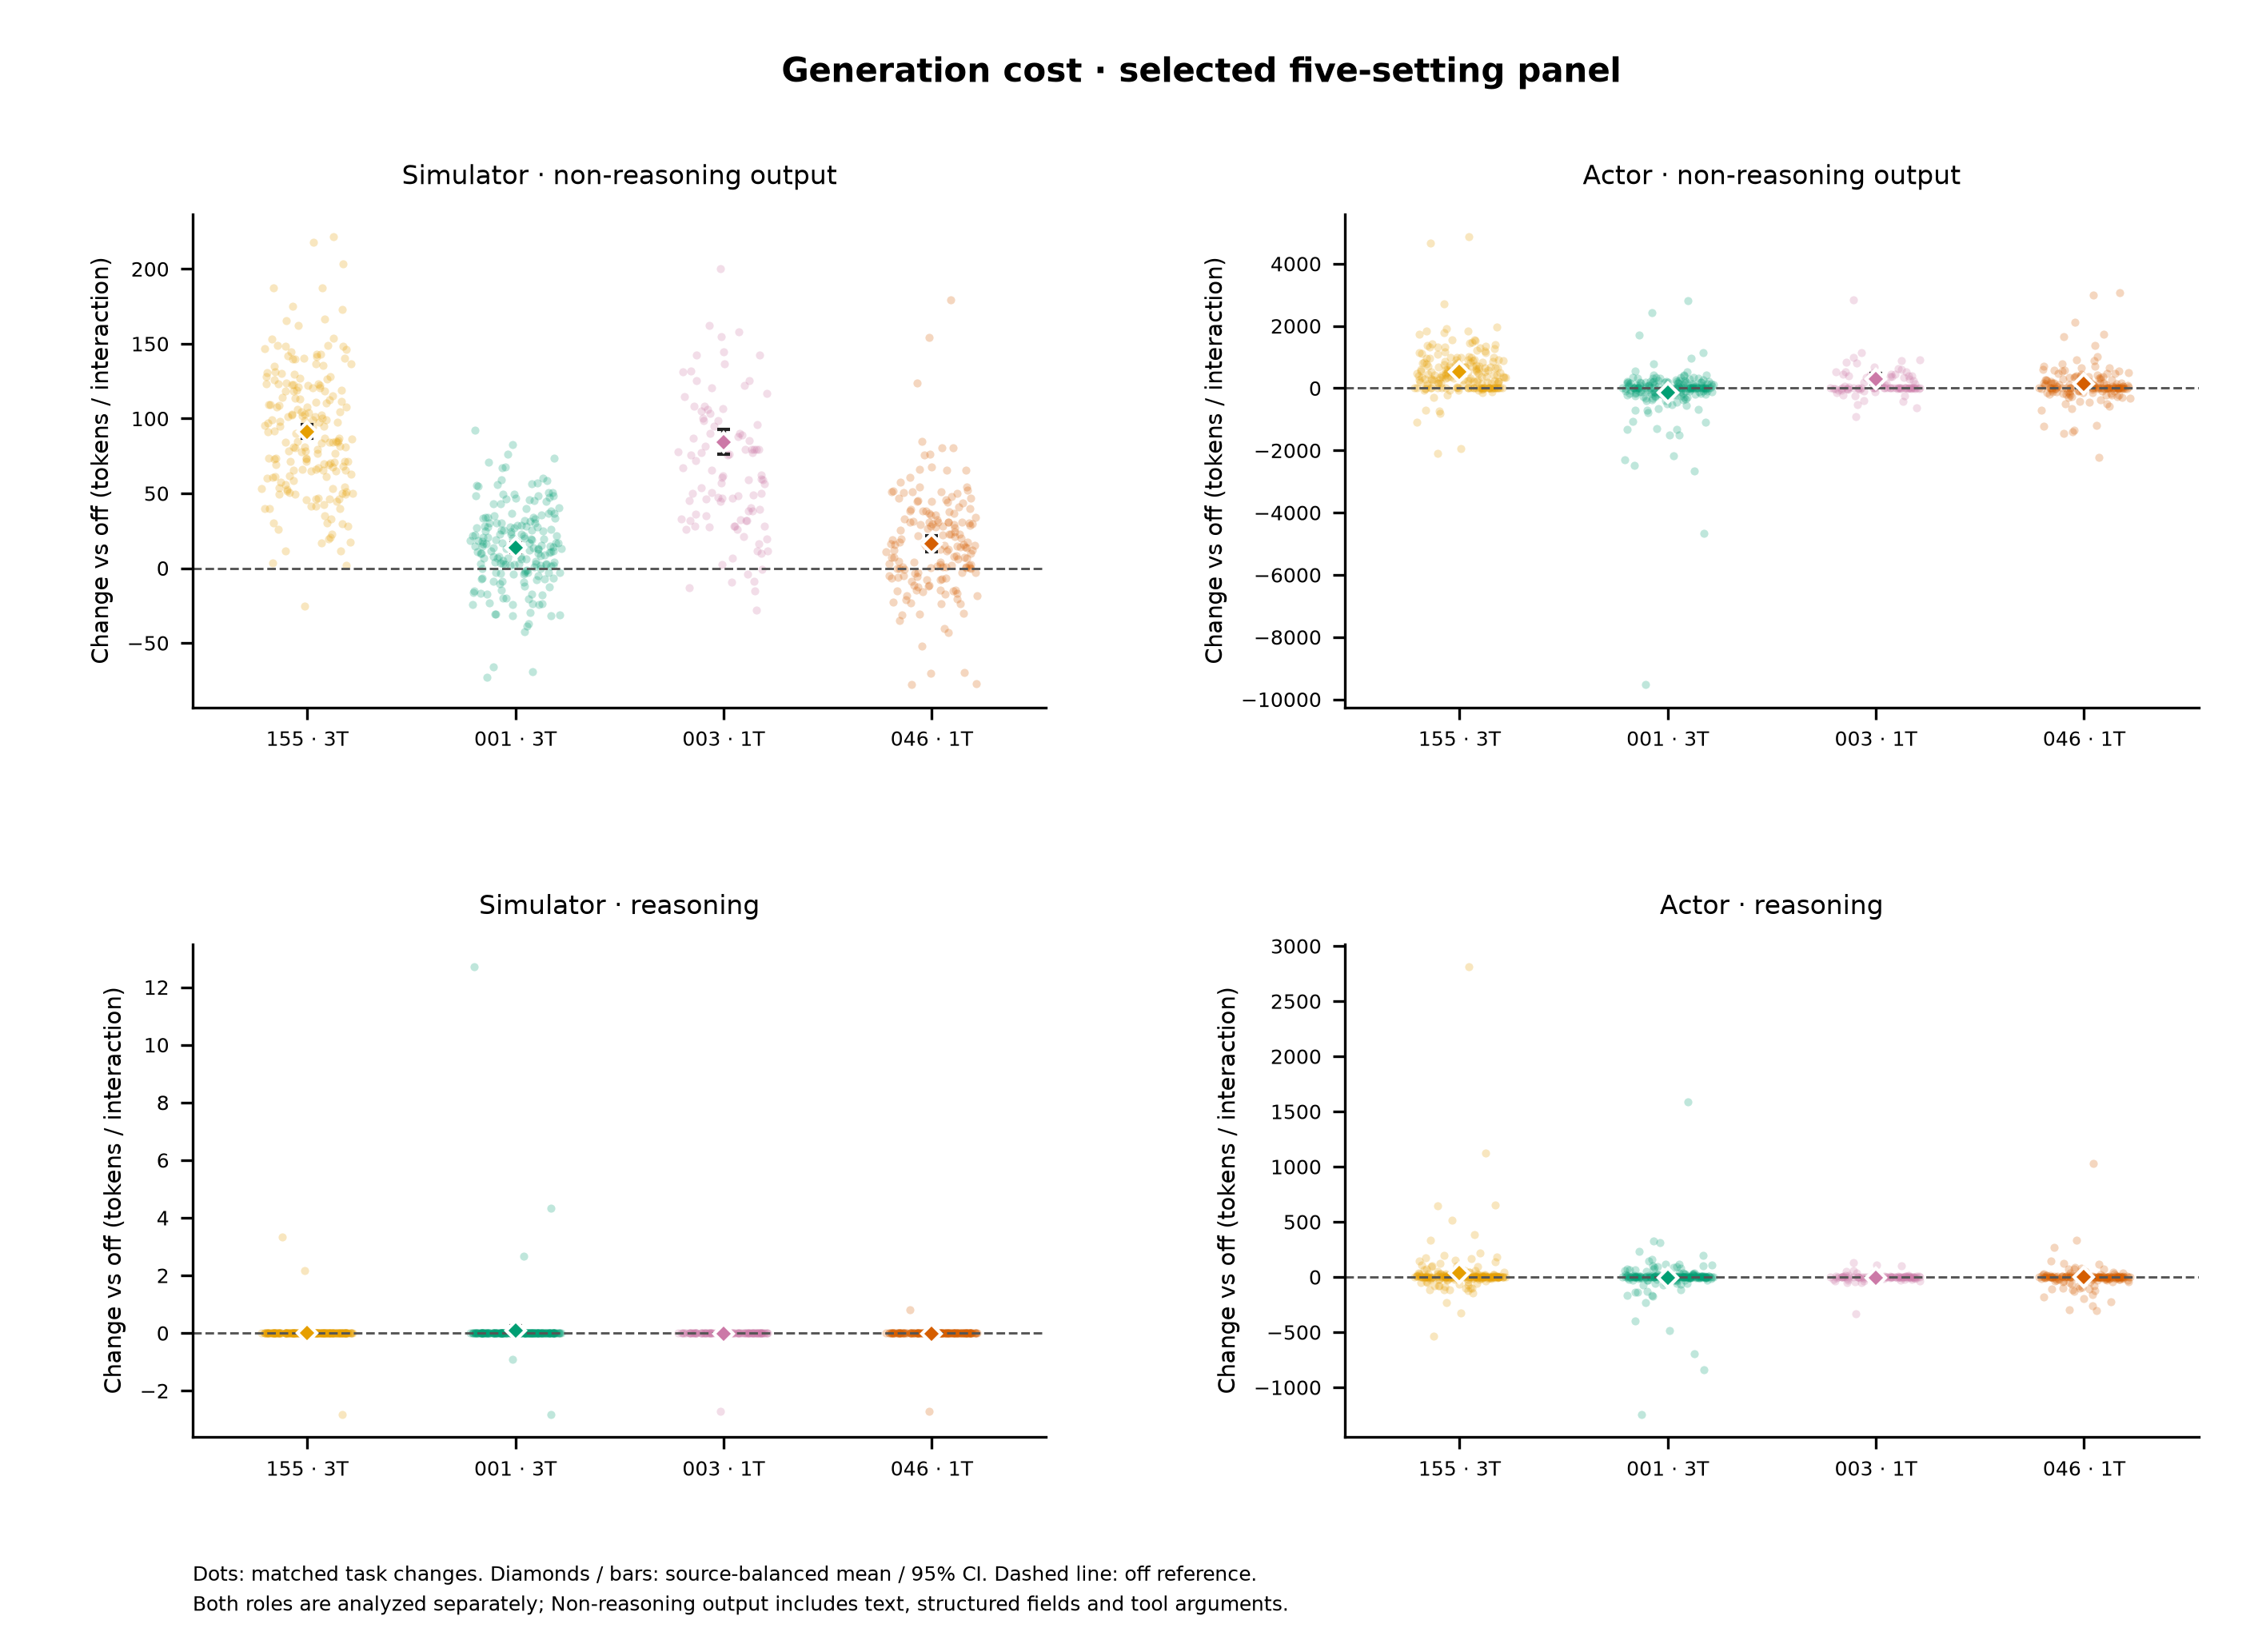

In [4]:
TOKEN_METRICS=['simulator_nonreasoning_tokens','actor_nonreasoning_tokens','simulator_reasoning_tokens','actor_reasoning_tokens']
for metric in TOKEN_METRICS:
    metric_table(metric)
display(Markdown('**Supporting total output (non-reasoning + reasoning)**'))
for metric in ['simulator_tokens','actor_tokens']:
    metric_table(metric)
fig,axes=plt.subplots(2,2,figsize=(240/25.4,175/25.4))
fig.subplots_adjust(left=.085,right=.97,bottom=.13,top=.87,wspace=.35,hspace=.48)
rows=[r for r in selected_episodes if r['eligible']]
for ax,metric,title in zip(axes.flat,TOKEN_METRICS,['Simulator · non-reasoning output','Actor · non-reasoning output','Simulator · reasoning','Actor · reasoning']):
    point_values=[]
    for i,a in enumerate(ARMS[1:]):
        grouped=defaultdict(list)
        for r in paired(rows,metric,a):grouped[(r['source'],r['task_id'])].append(r['value'])
        yy=np.array([np.mean(v) for v in grouped.values()]);point_values.extend(yy)
        jitter=np.array([(int(hashlib.sha256((k[0]+k[1]).encode()).hexdigest()[:8],16)/0xffffffff-.5)*.44 for k in grouped])
        ax.scatter(i+jitter,yy,s=6,color=COLORS[i+1],alpha=.25,linewidths=0)
        stat=summary['paired'][metric]['all'][a];lo,hi=stat['ci95'];mean=stat['mean']
        ax.errorbar(i,mean,yerr=[[mean-lo],[hi-mean]],fmt='D',mfc=COLORS[i+1],mec='white',ecolor='#222222',markersize=4,capsize=2,zorder=5)
    ax.axhline(0,color='#555555',lw=.7,ls='--')
    ax.set_xticks(range(4),[label(a)+(' · 3T' if summary['planned_trials'][a]==3 else ' · 1T') for a in ARMS[1:]])
    ax.set_ylabel('Change vs off (tokens / interaction)');ax.set_title(title,pad=9)
    ax.set_xlim(-.55,3.55)
fig.text(.53,.95,'Generation cost · selected five-setting panel',ha='center',fontsize=10,weight='bold')
fig.text(.085,.025,'Dots: matched task changes. Diamonds / bars: source-balanced mean / 95% CI. Dashed line: off reference.\nBoth roles are analyzed separately; Non-reasoning output includes text, structured fields and tool arguments.',fontsize=6,linespacing=1.5)
checked_figure(fig,'selected_response_lengths',[list(axes.flat)])


### Supporting context: script and API tokens

Dominant-script agreement measures agreement between actor text and the preceding noninitial simulator reply. Labels are Unicode proxies (Latin, CJK, Devanagari, Other), requiring at least 20 letters and 60% dominance; they are not inferred languages. Script shares help interpret token-usage differences without eliminating all language effects. The older six-setting English-primary sensitivity remains in the historical report and is not a result for this five-setting panel.

Actual SciConv API usage is reported separately in [sciconv_tokens.ipynb](sciconv_tokens.ipynb). This notebook now uses recorded API output usage, including reasoning, rather than retokenized visible text. It is a different endpoint from visible-message length.

In [5]:
for metric in ['script_match','simulator_cjk_share','simulator_devanagari_share']:
    metric_table(metric)

**Actor/simulator dominant-script agreement (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 100.00 [100.00, 100.00]; n=185, e=515 | reference |
| 155 | 93.27 [90.43, 95.64]; n=182, e=449 | -6.68 [-9.58, -4.28]; n=179, e=433 |
| 001 | 93.72 [91.27, 95.98]; n=156, e=383 | -6.15 [-8.63, -3.86]; n=153, e=352 |
| 003 | 94.55 [90.33, 97.86]; n=84, e=84 | -5.47 [-9.63, -2.13]; n=82, e=82 |
| 046 | 100.00 [100.00, 100.00]; n=157, e=157 | +0.00 [0.00, 0.00]; n=150, e=150 |

**Simulator CJK letters (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.00 [0.00, 0.00]; n=196, e=557 | reference |
| 155 | 79.50 [78.20, 80.63]; n=197, e=536 | +79.47 [78.17, 80.60]; n=196, e=524 |
| 001 | 0.00 [0.00, 0.00]; n=199, e=561 | +0.00 [0.00, 0.00]; n=195, e=528 |
| 003 | 0.00 [0.00, 0.00]; n=103, e=103 | +0.00 [0.00, 0.00]; n=101, e=101 |
| 046 | 0.00 [0.00, 0.00]; n=174, e=174 | +0.00 [0.00, 0.00]; n=168, e=168 |

**Simulator Devanagari letters (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.00 [0.00, 0.00]; n=196, e=557 | reference |
| 155 | 0.00 [0.00, 0.00]; n=197, e=536 | +0.00 [0.00, 0.00]; n=196, e=524 |
| 001 | 43.08 [41.60, 44.53]; n=199, e=561 | +43.31 [41.78, 44.79]; n=195, e=528 |
| 003 | 0.00 [0.00, 0.00]; n=103, e=103 | +0.00 [0.00, 0.00]; n=101, e=101 |
| 046 | 0.00 [0.00, 0.00]; n=174, e=174 | +0.00 [0.00, 0.00]; n=168, e=168 |

## 2. Collaboration and review behavior

These metrics apply to ASI, Bix, Discovery and EXP, whose collaboration workflow requires a plan and result stage.

| Metric | Definition | Role |
|---|---|---|
| Additional approach reviews | max(number of approach reviews − 1, 0) | Main: deliberation beyond the required first review |
| Revision requests | Number of simulator decisions to continue during result review | Main: requests for further work, not proof of a completed revision |
| Additional result reviews | max(number of result reviews − 1, 0) | Supporting: additional review opportunities |
| Researcher/actor budget reached | Percentage of eligible episodes hitting the respective request/call cap | Supporting: protocol limit, not scientific difficulty |

The required workflow leaves little optional review variation. Keep null/small effects visible; do not interpret every mean difference as added diversity.

In [6]:
for metric in ['extra_plan_reviews','revision_requests']:
    metric_table(metric)

**Additional approach reviews**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.01 [0.00, 0.02]; n=158, e=445 | reference |
| 155 | 0.01 [0.00, 0.02]; n=159, e=425 | +0.00 [-0.02, 0.02]; n=158, e=413 |
| 001 | 0.00 [0.00, 0.01]; n=160, e=448 | -0.00 [-0.01, 0.00]; n=158, e=417 |
| 003 | 0.00 [0.00, 0.00]; n=64, e=64 | +0.00 [0.00, 0.00]; n=63, e=63 |
| 046 | 0.00 [0.00, 0.00]; n=136, e=136 | +0.00 [0.00, 0.00]; n=130, e=130 |

**Result-review requests to continue**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.08 [0.03, 0.14]; n=158, e=445 | reference |
| 155 | 0.08 [0.05, 0.12]; n=159, e=425 | +0.00 [-0.05, 0.05]; n=158, e=413 |
| 001 | 0.11 [0.07, 0.16]; n=160, e=448 | +0.03 [-0.02, 0.08]; n=158, e=417 |
| 003 | 0.09 [0.03, 0.18]; n=64, e=64 | +0.04 [0.00, 0.09]; n=63, e=63 |
| 046 | 0.03 [0.01, 0.06]; n=136, e=136 | -0.06 [-0.24, 0.04]; n=130, e=130 |

### Interaction counts: report by benchmark

SciConv counts completed clarification question–reply exchanges and can finish with zero clarification. The other four benchmarks count actor handoffs, including the normally required plan and result handoffs. Their counts have different meanings, so this section displays **benchmark-specific** results rather than a pooled interaction count.

In [7]:
for source in SOURCES:
    metric_table('exchanges',source)


**Completed handoffs or clarification replies** · ASI-Bench

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2.10 [2.04, 2.18]; n=38, e=93 | reference |
| 155 | 2.08 [1.98, 2.18]; n=39, e=96 | -0.03 [-0.15, 0.10]; n=38, e=88 |
| 001 | 2.12 [2.04, 2.21]; n=40, e=109 | +0.00 [-0.09, 0.09]; n=38, e=86 |
| 003 | 2.12 [2.00, 2.38]; n=8, e=8 | +0.00 [0.00, 0.00]; n=7, e=7 |
| 046 | 2.00 [2.00, 2.00]; n=23, e=23 | +0.00 [0.00, 0.00]; n=18, e=18 |

**Completed handoffs or clarification replies** · BixBench

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2.19 [2.04, 2.43]; n=40, e=117 | reference |
| 155 | 2.17 [2.07, 2.29]; n=40, e=117 | -0.03 [-0.20, 0.12]; n=40, e=115 |
| 001 | 2.23 [2.10, 2.40]; n=40, e=119 | +0.04 [-0.13, 0.21]; n=40, e=116 |
| 003 | 2.14 [2.00, 2.36]; n=28, e=28 | +0.11 [0.00, 0.31]; n=28, e=28 |
| 046 | 2.08 [2.00, 2.18]; n=37, e=37 | -0.24 [-0.91, 0.12]; n=37, e=37 |

**Completed handoffs or clarification replies** · DiscoveryBench

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2.02 [2.00, 2.06]; n=40, e=115 | reference |
| 155 | 2.06 [2.02, 2.11]; n=40, e=107 | +0.04 [0.02, 0.07]; n=40, e=105 |
| 001 | 2.07 [2.04, 2.12]; n=40, e=115 | +0.06 [0.02, 0.10]; n=40, e=110 |
| 003 | 2.09 [2.00, 2.21]; n=22, e=22 | +0.05 [0.00, 0.11]; n=22, e=22 |
| 046 | 2.05 [2.00, 2.11]; n=37, e=37 | +0.03 [-0.09, 0.11]; n=36, e=36 |

**Completed handoffs or clarification replies** · EXP-Bench

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2.00 [2.00, 2.00]; n=40, e=120 | reference |
| 155 | 2.01 [2.00, 2.03]; n=40, e=105 | +0.01 [0.00, 0.03]; n=40, e=105 |
| 001 | 2.04 [2.01, 2.07]; n=40, e=105 | +0.04 [0.01, 0.07]; n=40, e=105 |
| 003 | 2.00 [2.00, 2.00]; n=6, e=6 | +0.00 [0.00, 0.00]; n=6, e=6 |
| 046 | 2.00 [2.00, 2.00]; n=39, e=39 | +0.00 [0.00, 0.00]; n=39, e=39 |

**Completed handoffs or clarification replies** · SciConvBench

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 3.51 [2.61, 4.47]; n=40, e=120 | reference |
| 155 | 3.48 [2.63, 4.38]; n=40, e=120 | -0.03 [-0.33, 0.25]; n=40, e=120 |
| 001 | 3.30 [2.51, 4.17]; n=40, e=120 | -0.21 [-0.46, 0.02]; n=40, e=120 |
| 003 | 3.33 [2.50, 4.22]; n=40, e=40 | -0.28 [-0.62, 0.05]; n=40, e=40 |
| 046 | 3.38 [2.48, 4.33]; n=40, e=40 | -0.23 [-0.65, 0.20]; n=40, e=40 |

### Supporting workflow diagnostics

In [8]:
for metric in ['extra_result_reviews','request_budget_exhausted','actor_budget_exhausted']:
    metric_table(metric)


**Additional result reviews**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.07 [0.03, 0.13]; n=158, e=445 | reference |
| 155 | 0.08 [0.04, 0.11]; n=159, e=425 | +0.00 [-0.05, 0.05]; n=158, e=413 |
| 001 | 0.11 [0.07, 0.16]; n=160, e=448 | +0.04 [-0.01, 0.09]; n=158, e=417 |
| 003 | 0.09 [0.03, 0.18]; n=64, e=64 | +0.04 [0.00, 0.09]; n=63, e=63 |
| 046 | 0.03 [0.01, 0.06]; n=136, e=136 | -0.05 [-0.22, 0.04]; n=130, e=130 |

**Researcher budget reached (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.21 [0.00, 0.68]; n=158, e=445 | reference |
| 155 | 0.00 [0.00, 0.00]; n=159, e=425 | -0.21 [-0.68, 0.00]; n=158, e=413 |
| 001 | 0.00 [0.00, 0.00]; n=160, e=448 | -0.21 [-0.68, 0.00]; n=158, e=417 |
| 003 | 0.00 [0.00, 0.00]; n=64, e=64 | +0.00 [0.00, 0.00]; n=63, e=63 |
| 046 | 0.00 [0.00, 0.00]; n=136, e=136 | -0.68 [-2.14, 0.00]; n=130, e=130 |

**Actor call budget reached (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 0.00 [0.00, 0.00]; n=158, e=445 | reference |
| 155 | 0.00 [0.00, 0.00]; n=159, e=425 | +0.00 [0.00, 0.00]; n=158, e=413 |
| 001 | 0.00 [0.00, 0.00]; n=160, e=448 | +0.00 [0.00, 0.00]; n=158, e=417 |
| 003 | 0.00 [0.00, 0.00]; n=64, e=64 | +0.00 [0.00, 0.00]; n=63, e=63 |
| 046 | 0.00 [0.00, 0.00]; n=136, e=136 | +0.00 [0.00, 0.00]; n=130, e=130 |

## 3. Clarification and information seeking — SciConv only

| Metric | Definition | Interpretation |
|---|---|---|
| Clarification recall | Native judged count of missing entities/inconsistencies covered by questions ÷ total annotated issues × 100 | Breadth of questioning about annotated issues |
| Clarification precision | Native judged relevant-question count ÷ all asked questions × 100 | Focus of questioning |
| Questions after first simulator reply | max(number of actor clarification questions − 1, 0) | Questioning after exposure to persona-conditioned replies |
| Ten-reply limit reached | Percentage of episodes with at least ten simulator replies | Supporting stopping/cap diagnostic |

The first actor question precedes the first persona-conditioned reply. Recall/precision use saved native judgments, with no new LLM judging. Asking about an issue is **not** equivalent to recovering it in the final answer; recovery stays in Experiment 09. Disambiguation and inconsistency cases follow their native issue definitions. Invalid native fractions remain missing rather than being clipped.

In [9]:
for metric in ['clarification_recall','clarification_precision','post_reply_questions','question_cap_hit']:
    metric_table(metric)

**Clarification recall (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 70.28 [58.06, 81.76]; n=40, e=120 | reference |
| 155 | 72.82 [61.66, 83.25]; n=40, e=120 | +2.53 [-1.84, 7.67]; n=40, e=120 |
| 001 | 72.54 [60.66, 83.78]; n=40, e=120 | +2.26 [-2.12, 7.50]; n=40, e=120 |
| 003 | 75.45 [63.57, 86.25]; n=40, e=40 | +0.31 [-6.25, 7.50]; n=40, e=40 |
| 046 | 76.77 [65.09, 87.25]; n=40, e=40 | +1.64 [-6.07, 10.39]; n=40, e=40 |

**Clarification precision (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 54.39 [42.74, 66.02]; n=40, e=120 | reference |
| 155 | 55.19 [44.07, 66.16]; n=40, e=120 | +0.80 [-2.29, 4.32]; n=40, e=120 |
| 001 | 53.63 [42.60, 64.63]; n=40, e=120 | -0.76 [-7.62, 5.38]; n=40, e=120 |
| 003 | 57.88 [46.23, 69.44]; n=40, e=40 | +4.78 [-0.62, 11.68]; n=40, e=40 |
| 046 | 58.46 [46.19, 70.38]; n=40, e=40 | +5.36 [-2.95, 14.65]; n=40, e=40 |

**SciConv questions after first simulator reply**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 2.58 [1.70, 3.52]; n=40, e=120 | reference |
| 155 | 2.54 [1.72, 3.42]; n=40, e=120 | -0.03 [-0.33, 0.25]; n=40, e=120 |
| 001 | 2.36 [1.58, 3.21]; n=40, e=120 | -0.22 [-0.47, 0.01]; n=40, e=120 |
| 003 | 2.35 [1.52, 3.25]; n=40, e=40 | -0.30 [-0.62, 0.03]; n=40, e=40 |
| 046 | 2.42 [1.52, 3.38]; n=40, e=40 | -0.23 [-0.65, 0.20]; n=40, e=40 |

**Ten-reply limit reached (%)**

| Setting | Mean [95% CI]; tasks/episodes | Paired change vs off [95% CI]; tasks/pairs |
|---|---|---|
| Off | 10.00 [2.50, 19.19]; n=40, e=120 | reference |
| 155 | 7.50 [1.67, 15.00]; n=40, e=120 | -2.50 [-7.50, 1.67]; n=40, e=120 |
| 001 | 6.67 [0.83, 15.00]; n=40, e=120 | -3.33 [-9.17, 0.00]; n=40, e=120 |
| 003 | 7.50 [0.00, 17.50]; n=40, e=40 | -2.50 [-7.50, 0.00]; n=40, e=40 |
| 046 | 7.50 [0.00, 17.50]; n=40, e=40 | -2.50 [-7.50, 0.00]; n=40, e=40 |

## 4. Selected-panel behavioral overview and repeat-data limits

The heatmap summarizes **155/001/003/046 relative to Off**, the same five settings used throughout this notebook. Cell text shows raw paired changes and pointwise 95% CIs; color scales changes by the matched baseline task SD. There is no significance-star selection. Undefined baseline SD is gray, not zero effect. Direction has no universal desirable interpretation.

A change in mean behavior does not by itself establish diversity beyond rollout randomness. The historical six-setting repeat-variation figure does not match this five-setting panel and is intentionally not displayed. Off/155/001 have repeats; 003/046 do not, so a full five-setting within-versus-between-repeat comparison is unavailable. Do not substitute historical six-setting estimates or manufacture repeats. Historical results remain in [ALL_PERSONAS_BEHAVIOR.md](ALL_PERSONAS_BEHAVIOR.md).


The four token columns separate simulator non-reasoning/reasoning and actor non-reasoning/reasoning. Token units are per simulator decision/reply or per completed actor interaction, not billed input tokens. Non-reasoning output includes structured fields/tool arguments. Other metric estimates are unchanged.

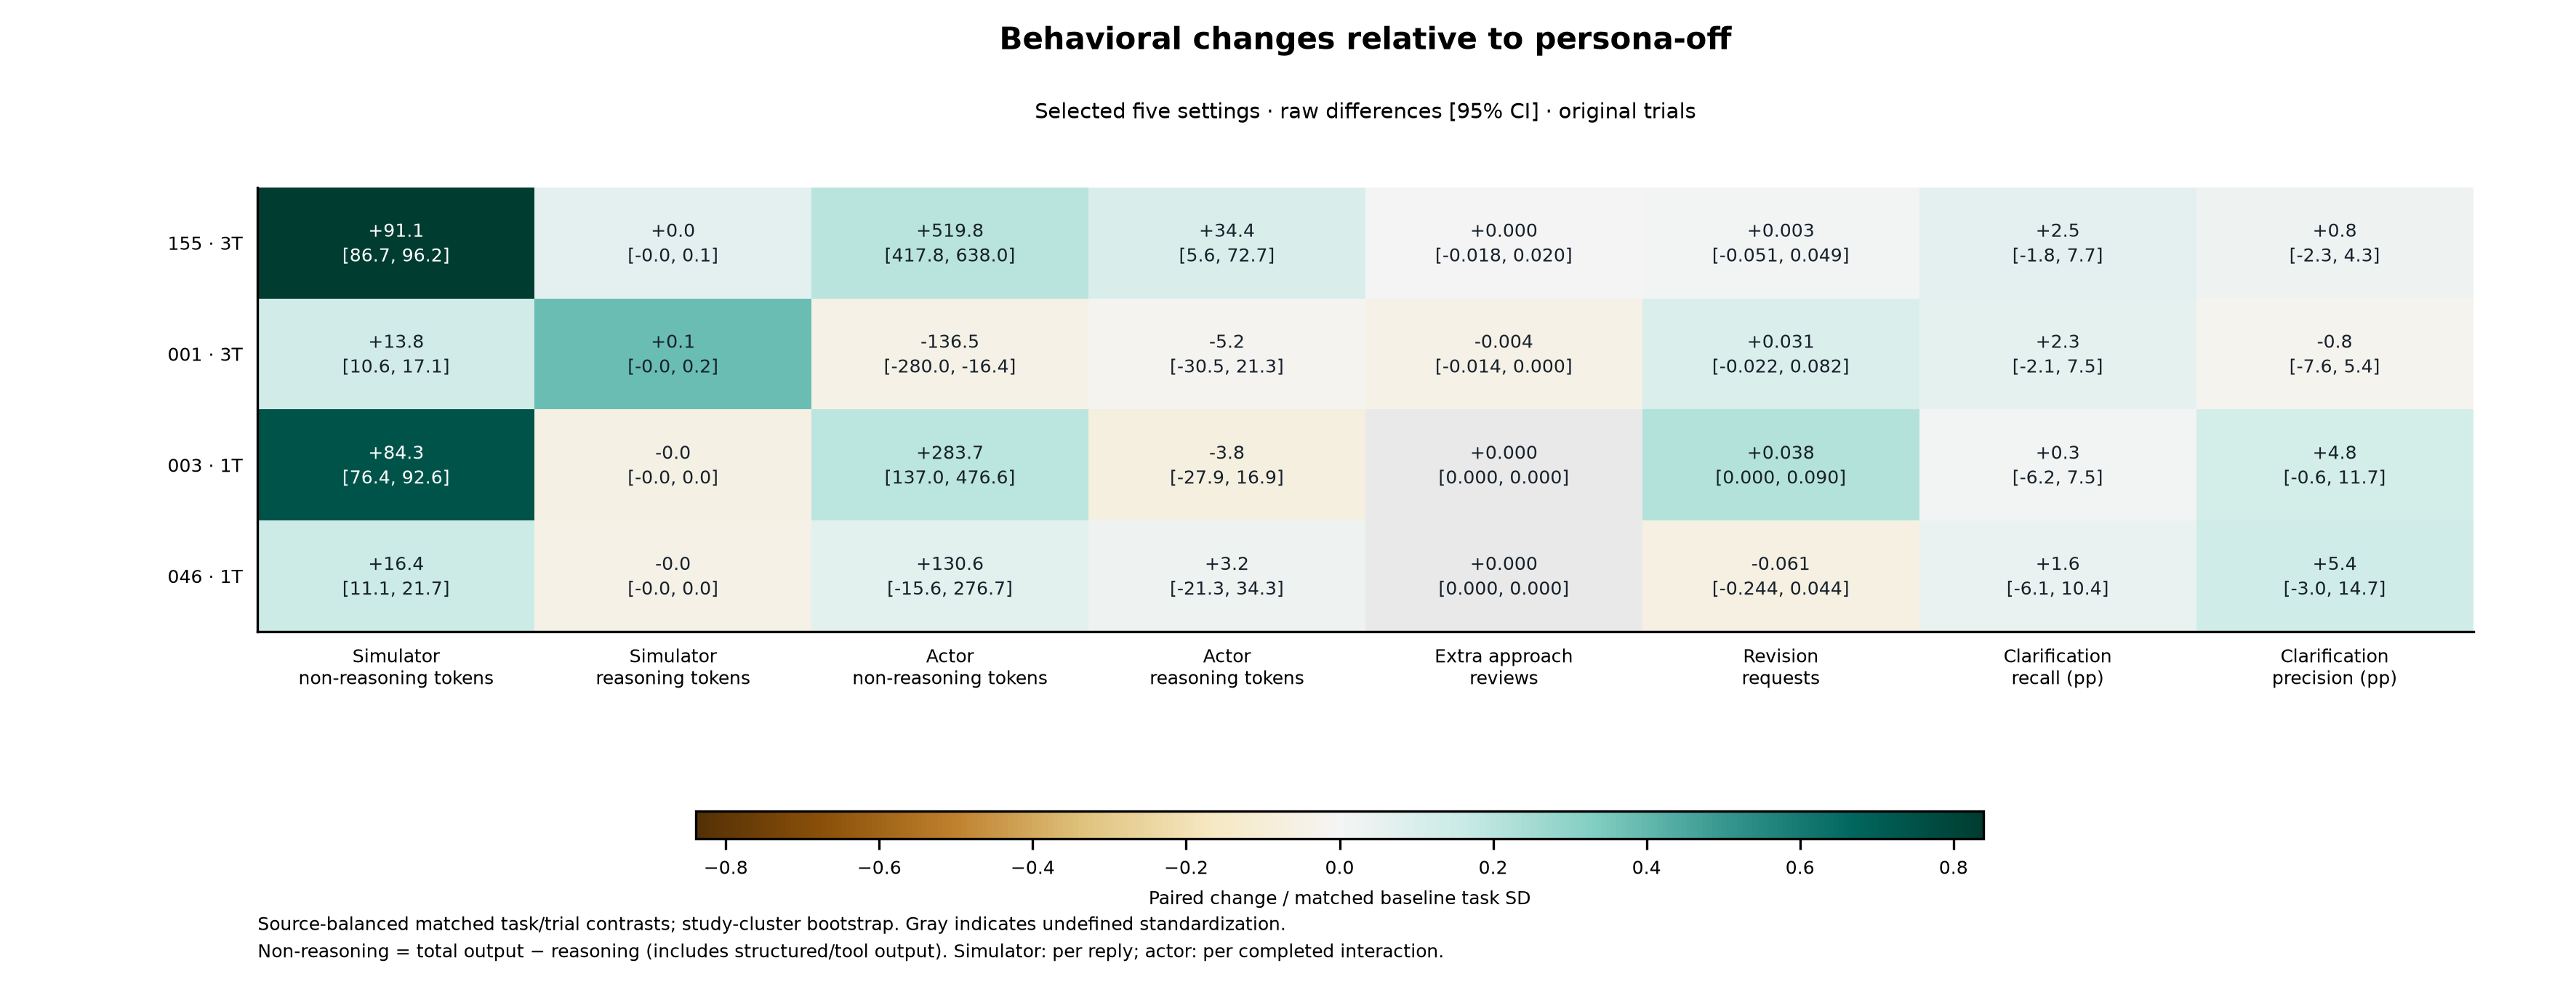

In [10]:
metrics=['simulator_nonreasoning_tokens','simulator_reasoning_tokens','actor_nonreasoning_tokens','actor_reasoning_tokens','extra_plan_reviews','revision_requests','clarification_recall','clarification_precision']
labels=['Simulator\nnon-reasoning tokens','Simulator\nreasoning tokens','Actor\nnon-reasoning tokens','Actor\nreasoning tokens','Extra approach\nreviews','Revision\nrequests','Clarification\nrecall (pp)','Clarification\nprecision (pp)']
values=np.array([[summary['paired'][m]['all'][a]['standardized_delta'] if summary['paired'][m]['all'][a]['standardized_delta'] is not None else np.nan for m in metrics] for a in ARMS[1:]])
bound=max(.1,float(np.nanmax(np.abs(values))))
fig,ax=plt.subplots(figsize=(300/25.4,115/25.4));fig.subplots_adjust(left=.10,right=.96,bottom=.36,top=.81)
cmap=plt.get_cmap('BrBG').copy();cmap.set_bad('#E9E9E9')
im=ax.imshow(values,cmap=cmap,norm=TwoSlopeNorm(vmin=-bound,vcenter=0,vmax=bound),aspect='auto')
ax.set_yticks(range(4),[label(a)+(' · 3T' if summary['planned_trials'][a]==3 else ' · 1T') for a in ARMS[1:]])
ax.set_xticks(range(len(metrics)),labels);ax.tick_params(length=0,pad=5)
for i,a in enumerate(ARMS[1:]):
    for j,m in enumerate(metrics):
        stat=summary['paired'][m]['all'][a];lo,hi=stat['ci95'];mean=stat['mean']
        fmt='.1f' if 'tokens' in m else '.3f' if m in ['extra_plan_reviews','revision_requests'] else '.1f'
        color='white' if np.isfinite(values[i,j]) and abs(values[i,j])>bound*.64 else '#17212B'
        ax.text(j,i,f'{mean:+{fmt}}\n[{lo:{fmt}}, {hi:{fmt}}]',ha='center',va='center',fontsize=6,color=color,linespacing=1.4)
cax=fig.add_axes([.27,.15,.50,.028]);cb=fig.colorbar(im,cax=cax,orientation='horizontal');cb.set_label('Paired change / matched baseline task SD',fontsize=6);cb.ax.tick_params(labelsize=6)
fig.text(.53,.95,'Behavioral changes relative to persona-off',ha='center',fontsize=10,weight='bold')
fig.text(.53,.88,'Selected five settings · raw differences [95% CI] · original trials',ha='center',fontsize=7)
fig.text(.10,.03,'Source-balanced matched task/trial contrasts; study-cluster bootstrap. Gray indicates undefined standardization.\nNon-reasoning = total output − reasoning (includes structured/tool output). Simulator: per reply; actor: per completed interaction.',fontsize=6,linespacing=1.5)
checked_figure(fig,'selected_behavior_effects',[[ax]],exclude=[cax])


## Interpretation and paper placement

The main evidence here is the selected five-setting communication, collaboration and clarification profile. Matched contrasts retain all available completed original trials (three for Off/155/001, one for 003/046) with explicit task/pair counts. Small/null review differences remain visible. API token use includes reasoning and structured/tool generation, depends on language and workflow, and is not information quality.

Within-conversation repetition and fact recovery remain in Experiment 09. Semantic and performance results retain separate notebooks. Behavioral measures do not establish human realism. A full five-setting comparison against within-persona rollout randomness requires repeats for 003 and 046; the historical six-setting comparison must not be presented as evidence for this selected panel.

The full expanded cohort, old lexical diagnostics, native grounding/intent/memory outcomes and six-setting repeat sensitivities remain in the archived reports and frozen input. No old results are deleted or silently reattributed to these five settings.

**Reproduction:** execute this notebook to load frozen `data/behavior_all_personas/snapshot.json` and `summary.json`, select the five arms, extract recorded API usage and recompute token metrics, and regenerate the embedded figures. Plot exports and alignment/font/collision checks use a temporary directory. API usage is extracted locally from saved call logs; no inference, data/report rewrite, or repository figure export occurs. Captions and tables in this notebook are the authoritative selected-panel description.


In [11]:
assert summary['invalid_native_metric_episodes']==0
assert sum(summary['coverage'][a].get('analyzed',0) for a in ARMS)==sum(r['eligible'] for r in selected_episodes)==1958
assert set(ARMS)=={r['arm'] for r in selected_episodes}
assert len(ARMS)==5 and ARMS==['persona_off','candidate_155','candidate_001','candidate_003','candidate_046']
assert all(summary['planned_trials'][a]==1 for a in ['candidate_003','candidate_046'])
print('Validated: selected five settings, 2,200 planned slots, 1,958 complete episodes; figures and tables use the same selected cohort.')

for r in selected_episodes:
    for role in ['simulator','actor']:
        nonreason=r.get(role+'_nonreasoning_tokens');reason=r.get(role+'_reasoning_tokens');total=r.get(role+'_tokens')
        if nonreason is not None:assert abs(nonreason+reason-total)<1e-9
print('Validated: non-reasoning output + reasoning = total output for every eligible episode/role.')


Validated: selected five settings, 2,200 planned slots, 1,958 complete episodes; figures and tables use the same selected cohort.
Validated: non-reasoning output + reasoning = total output for every eligible episode/role.


## Paired behavioral comparisons
Four lower-triangle heatmaps: **A simulator output tokens, B actor output tokens, C clarification recall, D actor tool use**. Tokens include reasoning and cover whole episodes; A/B share color limits. All eligible matched episodes are retained regardless of outcome. Each cell is row minus column.
The revision-request panel was omitted after reviewing its nonsignificant results; its comparisons remain in the original 50-test Holm correction and saved source data. Star definitions appear below the figure.


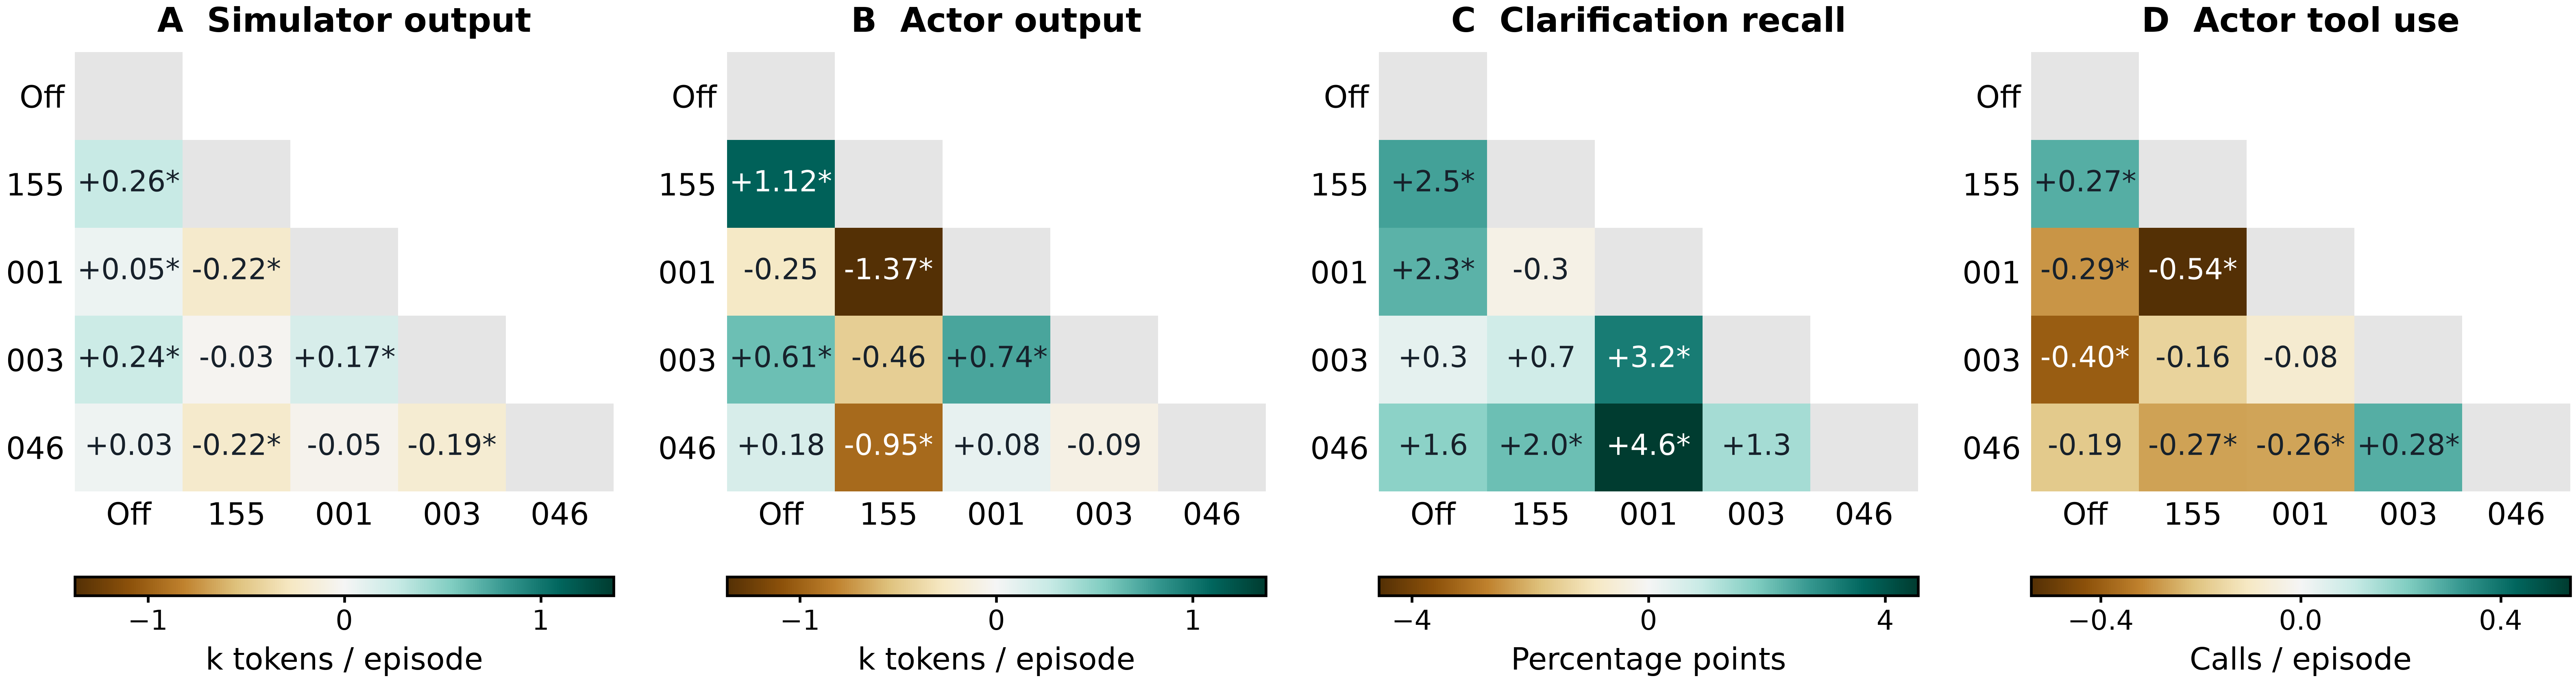

**Row − column. Star key: A/B, Holm-adjusted p < 0.20 across 50 comparisons; C, absolute difference > 2 percentage points; D, absolute difference > 0.2 calls/episode. C/D stars highlight user-selected effect-size thresholds, not statistical significance or 95% confidence. Thresholds were selected after inspection.**

Saved: /net/spaces/scratch/siyangwu-scratch2/PersonaScienceBench/Experiment/01_behavioral_diversity/figures/compact_behavior/pairwise_behavior_four.pdf


In [1]:
from pathlib import Path
import sys,json
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code'))
import compact_behavior
# Offline refresh from recorded logs only; cached comparisons suffice for redrawing.
RECOMPUTE_COMPACT=False
compact_summary=(compact_behavior.analyze(compact_behavior.extract()) if RECOMPUTE_COMPACT else json.loads((compact_behavior.DATA/'summary.json').read_text()))
compact_figure_dir=compact_behavior.plot(compact_summary)
compact_report=compact_behavior.report(compact_summary)
display(Image(filename=str(compact_figure_dir/'pairwise_behavior_four.png'),width=1450))
display(Markdown('**Row − column. '+compact_behavior.STAR_NOTE+'**'))
print('Saved:',compact_figure_dir/'pairwise_behavior_four.pdf')


## 6. Effect sizes, significance, coverage and source data

The actor tool-use comparison is now panel D of the combined figure rather than a separate heatmap. Its recorded execution/inspection actions exclude researcher handoffs. Complete methods, pointwise CIs, Holm-adjusted p values and sample counts follow. [CSV](data/compact_behavior/comparisons.csv) · [caption and results](COMPACT_BEHAVIOR.md) · [PDF](figures/compact_behavior/pairwise_behavior_four.pdf).


In [2]:
display(Markdown(compact_report))


# Compact paired behavioral analysis

**Four-panel behavioral comparison.** Cells show row minus column for Off/155/001/003/046. A: simulator episode-total output tokens; B: actor episode-total output tokens. Both include reasoning, are expressed in thousands, and share color limits. C: mean per-episode clarification recall (percentage-point differences). D: actor tool calls per episode. All four panels show lower triangles; gray diagonal denotes self-comparison. All eligible matched episodes are included regardless of final performance. Tool use applies to four execution/design sources; clarification recall applies to SciConv. Match question/trial before averaging, then equally weight questions within benchmarks and available benchmarks. Coverage varies by metric/pair. Revision requests were removed from this display after inspection of nonsignificant results; their ten tests remain in the original 50-comparison Holm correction and source-data tables. Star key: A/B, Holm-adjusted p < 0.20 across 50 comparisons; C, absolute difference > 2 percentage points; D, absolute difference > 0.2 calls/episode. C/D stars highlight user-selected effect-size thresholds, not statistical significance or 95% confidence. Thresholds were selected after inspection.

Stars alongside p values in the tables below indicate Holm-adjusted p < 0.20 only; these statistical flags are distinct from the C/D figure highlights.

## A  Simulator output

| Row − column | Difference [95% CI] | Holm p | Questions | Episode pairs | Questions by source |
|---|---|---|---|---|---|
| 155 − Off | +0.263 [+0.242, +0.287] | 0.0005* | 196 | 525 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 38} |
| 001 − Off | +0.048 [+0.034, +0.061] | 0.0005* | 195 | 528 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 37} |
| 001 − 155 | -0.217 [-0.239, -0.197] | 0.0005* | 196 | 514 | {"asibench": 39, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 37} |
| 003 − Off | +0.236 [+0.217, +0.258] | 0.0005* | 101 | 101 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6, "sciconvbench": 38} |
| 003 − 155 | -0.030 [-0.062, -0.003] | 1 | 101 | 101 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6, "sciconvbench": 38} |
| 003 − 001 | +0.173 [+0.149, +0.200] | 0.0005* | 100 | 100 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 5, "sciconvbench": 38} |
| 046 − Off | +0.032 [+0.005, +0.054] | 0.6844 | 168 | 168 | {"asibench": 18, "bixbench": 37, "discoverybench": 36, "expbench": 39, "sciconvbench": 38} |
| 046 − 155 | -0.218 [-0.245, -0.195] | 0.0005* | 166 | 166 | {"asibench": 18, "bixbench": 37, "discoverybench": 34, "expbench": 39, "sciconvbench": 38} |
| 046 − 001 | -0.047 [-0.089, -0.014] | 0.2827 | 168 | 168 | {"asibench": 22, "bixbench": 37, "discoverybench": 36, "expbench": 36, "sciconvbench": 37} |
| 046 − 003 | -0.189 [-0.212, -0.168] | 0.0005* | 99 | 99 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 38} |

## B  Actor output

| Row − column | Difference [95% CI] | Holm p | Questions | Episode pairs | Questions by source |
|---|---|---|---|---|---|
| 155 − Off | +1.123 [+0.838, +1.451] | 0.0005* | 196 | 525 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 38} |
| 001 − Off | -0.252 [-0.548, -0.002] | 1 | 195 | 528 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 37} |
| 001 − 155 | -1.372 [-1.722, -1.058] | 0.0005* | 196 | 514 | {"asibench": 39, "bixbench": 40, "discoverybench": 40, "expbench": 40, "sciconvbench": 37} |
| 003 − Off | +0.611 [+0.290, +1.022] | 0.03744* | 101 | 101 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6, "sciconvbench": 38} |
| 003 − 155 | -0.455 [-0.745, -0.121] | 0.5065 | 101 | 101 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6, "sciconvbench": 38} |
| 003 − 001 | +0.741 [+0.423, +1.135] | 0.0032* | 100 | 100 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 5, "sciconvbench": 38} |
| 046 − Off | +0.180 [-0.152, +0.510] | 1 | 168 | 168 | {"asibench": 18, "bixbench": 37, "discoverybench": 36, "expbench": 39, "sciconvbench": 38} |
| 046 − 155 | -0.951 [-1.328, -0.598] | 0.0005* | 166 | 166 | {"asibench": 18, "bixbench": 37, "discoverybench": 34, "expbench": 39, "sciconvbench": 38} |
| 046 − 001 | +0.084 [-0.426, +0.550] | 1 | 168 | 168 | {"asibench": 22, "bixbench": 37, "discoverybench": 36, "expbench": 36, "sciconvbench": 37} |
| 046 − 003 | -0.095 [-0.615, +0.407] | 1 | 99 | 99 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 38} |

## C  Clarification recall

| Row − column | Difference [95% CI] | Holm p | Questions | Episode pairs | Questions by source |
|---|---|---|---|---|---|
| 155 − Off | +2.535 [-1.840, +7.674] | 1 | 40 | 120 | {"sciconvbench": 40} |
| 001 − Off | +2.257 [-2.118, +7.500] | 1 | 40 | 120 | {"sciconvbench": 40} |
| 001 − 155 | -0.278 [-4.950, +4.058] | 1 | 40 | 120 | {"sciconvbench": 40} |
| 003 − Off | +0.312 [-6.250, +7.500] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 003 − 155 | +0.714 [-5.089, +7.679] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 003 − 001 | +3.229 [-5.521, +12.396] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 046 − Off | +1.637 [-6.071, +10.387] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 046 − 155 | +2.039 [-5.000, +10.625] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 046 − 001 | +4.554 [-5.238, +14.970] | 1 | 40 | 40 | {"sciconvbench": 40} |
| 046 − 003 | +1.324 [-2.530, +7.188] | 1 | 40 | 40 | {"sciconvbench": 40} |

## D  Actor tool use

| Row − column | Difference [95% CI] | Holm p | Questions | Episode pairs | Questions by source |
|---|---|---|---|---|---|
| 155 − Off | +0.274 [-0.142, +0.729] | 1 | 158 | 413 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40} |
| 001 − Off | -0.288 [-0.632, +0.021] | 1 | 158 | 417 | {"asibench": 38, "bixbench": 40, "discoverybench": 40, "expbench": 40} |
| 001 − 155 | -0.539 [-0.890, -0.199] | 0.08056* | 159 | 403 | {"asibench": 39, "bixbench": 40, "discoverybench": 40, "expbench": 40} |
| 003 − Off | -0.401 [-1.135, +0.200] | 1 | 63 | 63 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6} |
| 003 − 155 | -0.165 [-0.645, +0.317] | 1 | 63 | 63 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 6} |
| 003 − 001 | -0.078 [-0.471, +0.278] | 1 | 62 | 62 | {"asibench": 7, "bixbench": 28, "discoverybench": 22, "expbench": 5} |
| 046 − Off | -0.192 [-0.580, +0.225] | 1 | 130 | 130 | {"asibench": 18, "bixbench": 37, "discoverybench": 36, "expbench": 39} |
| 046 − 155 | -0.266 [-0.561, +0.047] | 1 | 128 | 128 | {"asibench": 18, "bixbench": 37, "discoverybench": 34, "expbench": 39} |
| 046 − 001 | -0.265 [-0.766, +0.220] | 1 | 131 | 131 | {"asibench": 22, "bixbench": 37, "discoverybench": 36, "expbench": 36} |
| 046 − 003 | +0.278 [-0.234, +0.922] | 1 | 61 | 61 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6} |

## Methods

Two-sided paired study-cluster sign flip; exact <=16 study blocks, otherwise 99,999 Monte Carlo draws with plus-one correction. Source-balanced weighted task differences; all tasks in a study share a sign. Requires independent study blocks and blockwise sign symmetry/exchangeability under the null.

Holm across the original 50 metric/persona-pair comparisons (including the undisplayed revision-request comparisons); one star for adjusted p<0.20, none otherwise. CIs are pointwise 95% study bootstrap, not multiplicity-adjusted.

All panels include all eligible matched episodes, without filtering on final performance. Metrics are calculated per episode before averaging; coverage varies by pair and metric.

Match source/question/trial, average repeats within question, then questions within benchmark and benchmarks equally. Pair/metric-specific coverage.

Actor and simulator recorded output separately per whole episode including reasoning, initial simulator decisions and final actor responses; no judge usage. Display in thousands.

Historical selected persona panel, unequal repeats and metric-specific availability; exploratory. The display threshold was changed to 0.20 after inspecting the results. Stars do not establish better adaptation or human realism.

Star key: A/B, Holm-adjusted p < 0.20 across 50 comparisons; C, absolute difference > 2 percentage points; D, absolute difference > 0.2 calls/episode. C/D stars highlight user-selected effect-size thresholds, not statistical significance or 95% confidence. Thresholds were selected after inspection.
